# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №2: Оценка экономической эффективности внедрения облачной CRM

**Дата:** 2026-10-22  
**Студент:** Ижедерова Виктория Денисовна  
**Группа:** ПИ-4.1  

---

**Цель:** Оценить экономическую эффективность внедрения облачной CRM-системы для отдела продаж компании «ТехноПром» с применением методов NPV, ROI, Payback Period и анализом нематериальных эффектов в контексте парадокса производительности Солоу.

**Объект исследования:** Отдел продаж компании «ТехноПром» (15 менеджеров).  
**Период анализа:** 3 года (горизонт планирования).  
**Методы анализа:** NPV, ROI, Payback Period, анализ нематериальных эффектов.

---

**Актуальность:** CRM-системы — ключевой инструмент автоматизации продаж. Однако их внедрение требует значительных инвестиций. Данная задача позволяет оценить, окупятся ли затраты на CRM и какой экономический эффект получит компания.

In [8]:
# ============================================================
# БЛОК 1: Импорт библиотек и загрузка исходных данных
# ============================================================
# Цель: Подключить инструменты для расчётов и визуализации,
# задать все параметры задачи из условия.
# ============================================================

# Импорт библиотек
import numpy as np                  # Математические вычисления
import pandas as pd                 # Работа с таблицами
import matplotlib.pyplot as plt     # Построение графиков
import seaborn as sns               # Красивые графики
import warnings                     # Отключение предупреждений
warnings.filterwarnings('ignore')

# Настройка внешнего вида графиков
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# ============================================================
# ИСХОДНЫЕ ДАННЫЕ (из условия задачи)
# ============================================================

n_managers = 15                     # Количество менеджеров в отделе продаж
salary_month = 120_000              # Средняя зарплата менеджера (руб./мес.)
routine_share = 0.30                # Доля времени на рутинные операции (30%)
crm_time_saving = 0.20              # Экономия времени на рутине после CRM (20%)
sales_growth = 0.08                 # Рост продаж после внедрения CRM (8% в год)
annual_revenue = 72_000_000         # Текущий годовой оборот отдела продаж (72 млн руб.)
license_per_user_year = 24_000      # Стоимость лицензии CRM на 1 пользователя в год (руб.)
adaptation_months = 1               # Время на обучение/адаптацию (1 месяц)
horizon = 3                         # Горизонт оценки (3 года)
discount_rate = 0.12                # Ставка дисконтирования (12% годовых)
tax_rate = 0.20                     # Налог на прибыль (20%)

print("Исходные данные загружены")
print(f"• Менеджеров: {n_managers} чел.")
print(f"• Зарплата: {salary_month:,} руб./мес.")
print(f"• Годовой оборот: {annual_revenue/1e6:.0f} млн руб.")
print(f"• Горизонт планирования: {horizon} года")

Исходные данные загружены
• Менеджеров: 15 чел.
• Зарплата: 120,000 руб./мес.
• Годовой оборот: 72 млн руб.
• Горизонт планирования: 3 года


# 1. ПРЯМОЙ ЭФФЕКТ ОТ ВНЕДРЕНИЯ CRM

**Цель:** Оценить непосредственные выгоды от внедрения CRM-системы.

Прямой эффект состоит из двух компонентов:
1. **Экономия на заработной плате** — за счёт автоматизации рутинных операций
2. **Дополнительный доход от роста продаж** — за счёт лучшего управления клиентами

---

## 1.1. Экономия на заработной плате

**Логика расчёта:**
- Менеджеры тратят 30% времени на рутину (отчёты, таблицы)
- CRM автоматизирует рутину и экономит 20% этого времени
- Итоговая экономия времени: 30% × 20% = 6% рабочего времени
- Это эквивалентно экономии 6% от фонда оплаты труда (ФОТ)

**Формулы:**

1. Годовой ФОТ:
   $$ФОТ = N_{менеджеров} \times Зарплата_{мес} \times 12$$

2. Доля сэкономленного времени:
   $$d = d_{рутины} \times d_{экономии}$$

3. Экономия на зарплате:
   $$Экономия = d \times ФОТ$$

---

## 1.2. Дополнительный доход от роста продаж

**Логика расчёта:**
- CRM помогает менеджерам лучше работать с клиентами
- Продажи вырастут на 8% в год
- Дополнительный доход = 8% от текущего оборота

**Формула:**
$$Доп.доход = g_{продаж} \times Выручка_{год}$$

In [10]:
# ============================================================
# БЛОК 2: Расчёт прямого эффекта от внедрения CRM
# ============================================================
# Цель: Оценить годовую выгоду от внедрения CRM
# (экономия на зарплате + дополнительный доход от продаж)
# ============================================================

# ----------------------------------------------------------
# 1.1. Экономия на заработной плате
# ----------------------------------------------------------

# Годовой фонд оплаты труда (ФОТ)
# Формула: ФОТ = 15 менеджеров × 120 000 руб/мес × 12 мес = 21.6 млн руб/год
annual_payroll = n_managers * salary_month * 12

# Доля сэкономленного времени
# Менеджеры тратят 30% времени на рутину, CRM экономит 20% этого времени
# Итого: 30% × 20% = 6% рабочего времени высвобождается
time_saving_share = routine_share * crm_time_saving

# Экономия на зарплате = 6% от годового ФОТ
# Формула: Экономия = 0.06 × 21.6 млн = 1.296 млн руб/год
salary_saving = time_saving_share * annual_payroll

print("1.1. Экономия на заработной плате")
print("-" * 55)
print(f"Годовой ФОТ: {annual_payroll:,.0f} руб.")
print(f"Доля сэкономленного времени: {time_saving_share*100:.1f}%")
print(f"  (рутина {routine_share*100:.0f}% × экономия {crm_time_saving*100:.0f}%)")
print(f"Экономия на зарплате: {salary_saving:,.0f} руб./год")

# ----------------------------------------------------------
# 1.2. Дополнительный доход от роста продаж
# ----------------------------------------------------------

# CRM помогает лучше работать с клиентами → продажи растут на 8%
# Формула: Доп.доход = 8% × 72 млн = 5.76 млн руб/год
extra_revenue = sales_growth * annual_revenue

print("\n1.2. Дополнительный доход от роста продаж")
print("-" * 55)
print(f"Рост продаж: {sales_growth*100:.0f}%")
print(f"Дополнительный доход: {extra_revenue:,.0f} руб./год")

# ----------------------------------------------------------
# Итого прямой эффект
# ----------------------------------------------------------

# Суммируем оба компонента
# Формула: Эффект = Экономия на ЗП + Доп.доход от продаж
total_effect = salary_saving + extra_revenue

print(f"\nИТОГО годовой прямой эффект: {total_effect:,.0f} руб.")
print(f"   ({total_effect/1e6:.3f} млн руб./год)")

# Экономическая интерпретация
print(f"\nЭкономический смысл:")
print(f"Внедрение CRM принесёт компании {total_effect/1e6:.3f} млн руб.")
print(f"дополнительной выгоды каждый год:")
print(f"  • {salary_saving/1e6:.3f} млн — за счёт автоматизации рутины")
print(f"  • {extra_revenue/1e6:.2f} млн — за счёт роста продаж")

1.1. Экономия на заработной плате
-------------------------------------------------------
Годовой ФОТ: 21,600,000 руб.
Доля сэкономленного времени: 6.0%
  (рутина 30% × экономия 20%)
Экономия на зарплате: 1,296,000 руб./год

1.2. Дополнительный доход от роста продаж
-------------------------------------------------------
Рост продаж: 8%
Дополнительный доход: 5,760,000 руб./год

ИТОГО годовой прямой эффект: 7,056,000 руб.
   (7.056 млн руб./год)

Экономический смысл:
Внедрение CRM принесёт компании 7.056 млн руб.
дополнительной выгоды каждый год:
  • 1.296 млн — за счёт автоматизации рутины
  • 5.76 млн — за счёт роста продаж


# 2. ЗАТРАТЫ НА ВНЕДРЕНИЕ

**Цель:** Оценить все расходы, связанные с внедрением CRM.

Затраты состоят из двух компонентов:
1. **Стоимость лицензий** — регулярные платежи за использование CRM (OPEX)
2. **Потери от адаптации** — разовые потери производительности при обучении

---

## 2.1. Стоимость лицензий за 3 года

**Логика расчёта:**
- CRM — облачный сервис (SaaS), компания платит подписку каждый год
- Стоимость: 24 000 руб. на 1 пользователя в год
- За 3 года: 15 менеджеров × 24 000 × 3 года

**Формула:**
$$Лицензии_{год} = N_{менеджеров} \times Цена_{лицензии}$$
$$Лицензии_{3года} = Лицензии_{год} \times 3$$

---

## 2.2. Потери от снижения производительности в период адаптации

**Логика расчёта:**
- Пока сотрудники учатся работать с CRM (1 месяц), они работают медленнее
- Это эквивалентно потере 1 месяца работы всего отдела
- Потери = Годовой ФОТ / 12 месяцев × 1 месяц

**Формула:**
$$Потери_{адаптации} = \frac{ФОТ}{12} \times T_{адаптации}$$

In [11]:
# ============================================================
# БЛОК 3: Расчёт затрат на внедрение CRM
# ============================================================
# Цель: Оценить все расходы за 3 года (лицензии + адаптация)
# ============================================================

# ----------------------------------------------------------
# 2.1. Стоимость лицензий за 3 года
# ----------------------------------------------------------

# Годовая стоимость лицензий для всего отдела
# Формула: 15 менеджеров × 24 000 руб/год = 360 000 руб/год
license_year = n_managers * license_per_user_year

# Стоимость лицензий за весь горизонт (3 года)
# Формула: 360 000 × 3 = 1.08 млн руб
license_total = license_year * horizon

print("2.1. Стоимость лицензий")
print("-" * 55)
print(f"Лицензии в год: {license_year:,.0f} руб.")
print(f"Лицензии за {horizon} года: {license_total:,.0f} руб.")

# ----------------------------------------------------------
# 2.2. Потери от адаптации (1 месяц)
# ----------------------------------------------------------

# Пока сотрудники учатся работать с CRM, они работают медленнее
# Это эквивалентно потере 1 месяца работы всего отдела
# Формула: (21.6 млн / 12) × 1 = 1.8 млн руб
adaptation_loss = (annual_payroll / 12) * adaptation_months

print(f"\n2.2. Потери от адаптации ({adaptation_months} месяц)")
print("-" * 55)
print(f"Потери в первый месяц: {adaptation_loss:,.0f} руб.")

# ----------------------------------------------------------
# Итого затрат за 3 года
# ----------------------------------------------------------

# Суммируем все затраты
# Формула: Затраты = Лицензии за 3 года + Потери от адаптации
total_costs = license_total + adaptation_loss

print(f"\nИТОГО затрат за {horizon} года: {total_costs:,.0f} руб.")
print(f"   ({total_costs/1e6:.2f} млн руб.)")

# Экономическая интерпретация
print(f"\nЭкономический смысл:")
print(f"Внедрение CRM обойдётся компании в {total_costs/1e6:.2f} млн руб. за 3 года:")
print(f"  • {license_total/1e6:.2f} млн — лицензии (регулярные платежи)")
print(f"  • {adaptation_loss/1e6:.2f} млн — потери от адаптации (разово)")
print(f"Это операционные расходы (OPEX), а не капитальные (CAPEX).")

2.1. Стоимость лицензий
-------------------------------------------------------
Лицензии в год: 360,000 руб.
Лицензии за 3 года: 1,080,000 руб.

2.2. Потери от адаптации (1 месяц)
-------------------------------------------------------
Потери в первый месяц: 1,800,000 руб.

ИТОГО затрат за 3 года: 2,880,000 руб.
   (2.88 млн руб.)

Экономический смысл:
Внедрение CRM обойдётся компании в 2.88 млн руб. за 3 года:
  • 1.08 млн — лицензии (регулярные платежи)
  • 1.80 млн — потери от адаптации (разово)
Это операционные расходы (OPEX), а не капитальные (CAPEX).


# 3. ФИНАНСОВЫЕ ПОКАЗАТЕЛИ ЭФФЕКТИВНОСТИ

**Цель:** Оценить экономическую эффективность проекта с помощью стандартных финансовых показателей.

---

## 3.1. Прирост чистой прибыли по годам (с учётом налога)

**Формулы:**

1. Прибыль до налогообложения (EBT):
   $$EBT = Эффект - Лицензии - Адаптация$$

2. Налог на прибыль (20%):
   $$Налог = EBT \times 20\%$$

3. Чистая прибыль:
   $$Чистая прибыль = EBT - Налог = EBT \times (1 - 0.20)$$

---

## 3.2. NPV проекта (r = 12%)

**NPV (Net Present Value)** — чистая приведённая стоимость. Показывает, сколько денег принесёт проект с учётом того, что деньги сегодня дороже денег завтра.

**Почему нужно дисконтирование?**
- Инфляция обесценивает деньги
- Можно положить деньги в банк под процент
- Будущее неопределённо (риск)

**Формула:**
$$NPV = \sum_{t=1}^{T} \frac{Прибыль_t}{(1 + r)^t}$$

Где:
- $r$ — ставка дисконтирования (12% = 0.12)
- $t$ — номер года
- $T$ — горизонт планирования (3 года)

**Правило:**
- NPV > 0 → проект выгоден 
- NPV < 0 → проект убыточен 

---

## 3.3. Простой срок окупаемости (Payback Period)

**Срок окупаемости** — время, за которое проект вернёт вложенные деньги.

**Формула:**
$$Payback = \frac{Инвестиции}{Годовой денежный поток}$$

---

## 3.4. ROI проекта

**ROI (Return on Investment)** — возврат на инвестиции. Показывает, сколько прибыли приносит каждый вложенный рубль.

**Формула:**
$$ROI = \frac{\sum Прибыль - Затраты}{Затраты} \times 100\%$$

**Интерпретация:**
- ROI > 0% → проект прибыльный 
- ROI > 100% → отличный проект 

In [12]:
# ============================================================
# БЛОК 4: Финансовые показатели эффективности
# ============================================================
# Цель: Рассчитать NPV, ROI, срок окупаемости и чистую прибыль
# по годам для оценки экономической эффективности проекта.
# ============================================================

# ----------------------------------------------------------
# 3.1. Чистая прибыль по годам
# ----------------------------------------------------------

# Массив лет: [1, 2, 3]
years = np.arange(1, horizon + 1)

# Эффект (доход) одинаковый каждый год: 7.056 млн руб.
effects = np.full(horizon, total_effect)

# Лицензии одинаковые каждый год: 360 000 руб.
licenses = np.full(horizon, license_year)

# Адаптация — только в 1-й год (1.8 млн), в остальные годы — 0
adaptation = np.zeros(horizon)
adaptation[0] = adaptation_loss  # адаптация[0] = 1 800 000

# Прибыль до налогообложения (EBT)
# Формула: EBT = Эффект − Лицензии − Адаптация
ebt = effects - licenses - adaptation

# Налог на прибыль (20%)
# Формула: Налог = EBT × 20%
tax = ebt * tax_rate

# Чистая прибыль (после налога)
# Формула: Чистая прибыль = EBT − Налог = EBT × (1 − 0.20)
net_profit = ebt - tax

# Формируем таблицу результатов
df = pd.DataFrame({
    'Год': years,
    'Эффект': effects,
    'Лицензии': licenses,
    'Адаптация': adaptation,
    'EBT': ebt,
    'Налог': tax,
    'Чистая прибыль': net_profit
})

print("3.1. Прирост чистой прибыли по годам")
print("=" * 75)
print(df.to_string(index=False))
print("=" * 75)

# Экономическая интерпретация
print(f"\nПочему в 1-й год прибыль меньше?")
print(f"В 1-й год есть дополнительные затраты на адаптацию ({adaptation_loss/1e6:.2f} млн руб.)")
print(f"— сотрудники учатся работать с CRM и работают медленнее.")
print(f"Во 2-й и 3-й год адаптации нет, только лицензии ({license_year/1e6:.2f} млн руб./год).")

# ----------------------------------------------------------
# 3.2. NPV проекта (r = 12%)
# ----------------------------------------------------------

# NPV — чистая приведённая стоимость
# Формула: NPV = Σ (Прибыль_t / (1 + r)^t)
# Дисконтирование учитывает, что деньги сегодня дороже денег завтра

npv = np.sum(net_profit / (1 + discount_rate) ** years)

print(f"\n3.2. NPV проекта (r={discount_rate*100:.0f}%)")
print("-" * 55)
print(f"NPV = {npv:,.0f} руб. = {npv/1e6:.2f} млн руб.")

if npv > 0:
    print(f"NPV > 0 → проект экономически эффективен")
    print(f"   Проект принесёт на {npv/1e6:.2f} млн руб. больше,")
    print(f"   чем если бы деньги положили в банк под {discount_rate*100:.0f}% годовых.")
else:
    print(f"NPV < 0 → проект убыточен")

# ----------------------------------------------------------
# 3.3. Простой срок окупаемости (Payback Period)
# ----------------------------------------------------------

# Срок окупаемости — время возврата вложенных денег
# Инвестиции = потери от адаптации (1.8 млн)
# Годовой денежный поток = чистая прибыль 1-го года (3.917 млн)

# Формула: Payback = Инвестиции / Годовой CF
payback_years = adaptation_loss / net_profit[0]
payback_months = payback_years * 12

print(f"\n3.3. Простой срок окупаемости")
print("-" * 55)
print(f"Инвестиции (адаптация): {adaptation_loss/1e6:.2f} млн руб.")
print(f"Годовой CF (1-й год): {net_profit[0]/1e6:.2f} млн руб.")
print(f"Срок окупаемости: {payback_years:.2f} года ≈ {payback_months:.1f} месяцев")

if payback_months < 12:
    print(f"Окупаемость менее 1 года — проект низкорисковый")

# ----------------------------------------------------------
# 3.4. ROI проекта
# ----------------------------------------------------------

# ROI — возврат на инвестиции
# Формула: ROI = (Суммарная прибыль − Затраты) / Затраты × 100%

total_net_profit = np.sum(net_profit)
roi = (total_net_profit - total_costs) / total_costs * 100
roi_per_year = roi / horizon

print(f"\n3.4. ROI проекта")
print("-" * 55)
print(f"Суммарная чистая прибыль за {horizon} года: {total_net_profit/1e6:.2f} млн руб.")
print(f"Суммарные затраты: {total_costs/1e6:.2f} млн руб.")
print(f"ROI за {horizon} года: {roi:.0f}%")
print(f"ROI в год (средний): {roi_per_year:.0f}%")

if roi > 100:
    print(f"ROI > 100% — отличная отдача на инвестиции!")
    print(f"   На каждый вложенный рубль компания получила {roi/100:.2f} руб. прибыли за 3 года.")

# ----------------------------------------------------------
# Сводная таблица результатов
# ----------------------------------------------------------
print(f"\n{'='*55}")
print(f"СВОДНЫЕ РЕЗУЛЬТАТЫ")
print(f"{'='*55}")
print(f"• Годовой эффект:      {total_effect/1e6:.3f} млн руб.")
print(f"• Затраты за 3 года:   {total_costs/1e6:.2f} млн руб.")
print(f"• NPV (r=12%):         {npv/1e6:.2f} млн руб. ")
print(f"• Срок окупаемости:    {payback_months:.1f} месяцев ")
print(f"• ROI за 3 года:       {roi:.0f}% ")
print(f"{'='*55}")

3.1. Прирост чистой прибыли по годам
 Год    Эффект  Лицензии  Адаптация       EBT     Налог  Чистая прибыль
   1 7056000.0    360000  1800000.0 4896000.0  979200.0       3916800.0
   2 7056000.0    360000        0.0 6696000.0 1339200.0       5356800.0
   3 7056000.0    360000        0.0 6696000.0 1339200.0       5356800.0

Почему в 1-й год прибыль меньше?
В 1-й год есть дополнительные затраты на адаптацию (1.80 млн руб.)
— сотрудники учатся работать с CRM и работают медленнее.
Во 2-й и 3-й год адаптации нет, только лицензии (0.36 млн руб./год).

3.2. NPV проекта (r=12%)
-------------------------------------------------------
NPV = 11,580,415 руб. = 11.58 млн руб.
NPV > 0 → проект экономически эффективен
   Проект принесёт на 11.58 млн руб. больше,
   чем если бы деньги положили в банк под 12% годовых.

3.3. Простой срок окупаемости
-------------------------------------------------------
Инвестиции (адаптация): 1.80 млн руб.
Годовой CF (1-й год): 3.92 млн руб.
Срок окупаемости: 0.46 го

## 3.5. Визуализация денежных потоков

**График 1: Чистая прибыль по годам**
- Зелёные столбцы — чистая прибыль каждого года
- Красная линия — накопленная прибыль (сумма за все годы)
- Показывает рост прибыли и накопленный эффект проекта

**График 2: Эффекты vs Затраты по годам**
- Синие столбцы — доход от CRM (эффект)
- Красные столбцы — затраты (лицензии + адаптация)
- Показывает, что эффект значительно превышает затраты

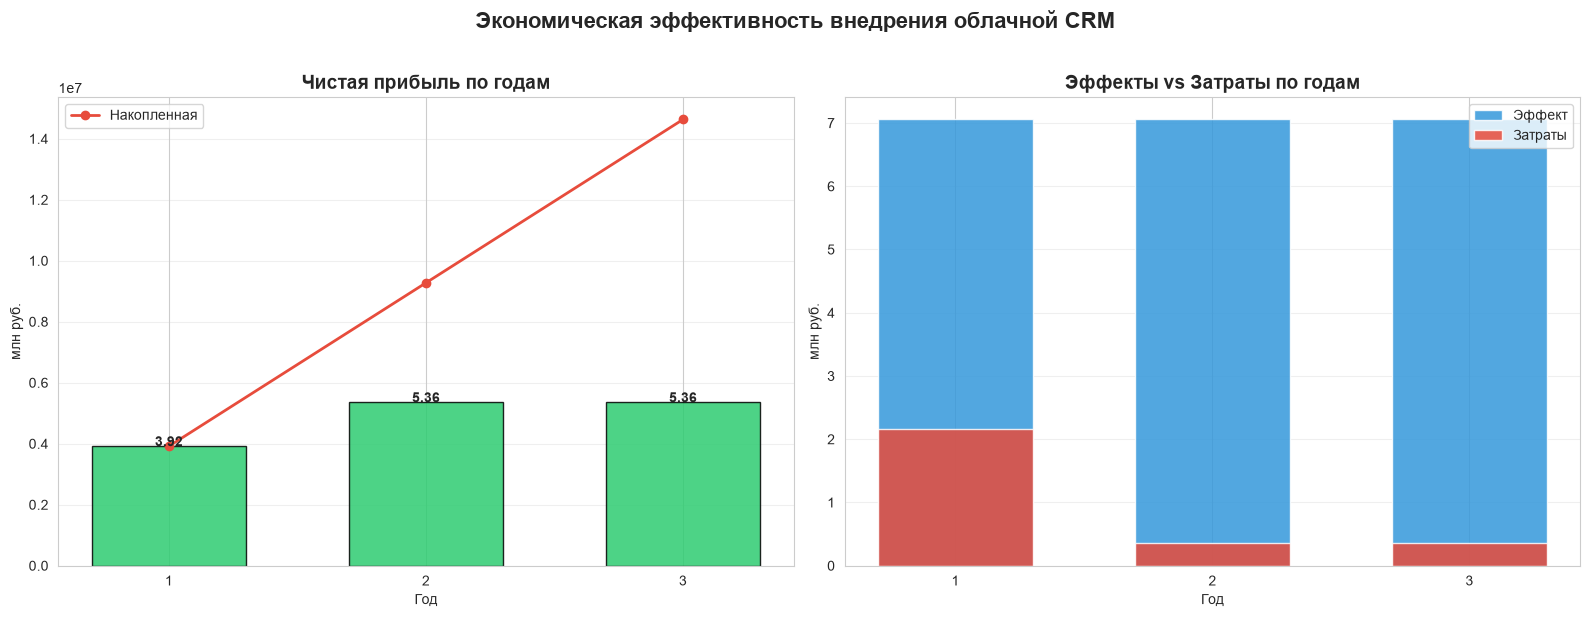

 Графики построены


In [13]:
# ============================================================
# БЛОК 5: Визуализация денежных потоков
# ============================================================
# Цель: Построить наглядные графики для анализа эффективности
# проекта внедрения CRM.
# ============================================================

# Создаём фигуру с 2 графиками рядом
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Позиции для столбцов на оси X (годы 1, 2, 3)
x_positions = [1, 2, 3]

# ----------------------------------------------------------
# ГРАФИК 1: Чистая прибыль по годам
# ----------------------------------------------------------

# Зелёные столбцы — чистая прибыль каждого года
axes[0].bar(x_positions, net_profit, color='#2ECC71', alpha=0.85,
            edgecolor='black', width=0.6)

# Красная линия — накопленная прибыль (сумма за все годы)
# np.cumsum() считает кумулятивную сумму: [3.92, 9.28, 14.64]
axes[0].plot(x_positions, np.cumsum(net_profit), 'o-',
             color='#E74C3C', linewidth=2, label='Накопленная')

# Настройка осей и заголовка
axes[0].set_title('Чистая прибыль по годам', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Год')
axes[0].set_ylabel('млн руб.')
axes[0].set_xticks(x_positions)
axes[0].set_xticklabels(['1', '2', '3'])
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Подписи значений на столбцах (в млн руб.)
for i, v in enumerate(net_profit):
    axes[0].text(x_positions[i], v + 0.1, f'{v/1e6:.2f}',
                 ha='center', fontweight='bold')

# ----------------------------------------------------------
# ГРАФИК 2: Эффекты vs Затраты по годам
# ----------------------------------------------------------

# Синие столбцы — эффект (доход) от CRM каждый год
axes[1].bar(x_positions, effects/1e6, color='#3498DB', alpha=0.85,
            width=0.6, label='Эффект')

# Красные столбцы — затраты (лицензии + адаптация)
# В 1-й год затраты больше из-за адаптации (2.16 млн)
# Во 2-й и 3-й год — только лицензии (0.36 млн)
axes[1].bar(x_positions, (licenses+adaptation)/1e6, color='#E74C3C',
            alpha=0.85, width=0.6, label='Затраты')

# Настройка осей и заголовка
axes[1].set_title('Эффекты vs Затраты по годам', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Год')
axes[1].set_ylabel('млн руб.')
axes[1].set_xticks(x_positions)
axes[1].set_xticklabels(['1', '2', '3'])
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

# Общий заголовок для обоих графиков
plt.suptitle('Экономическая эффективность внедрения облачной CRM',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(" Графики построены")

# 4. НЕМАТЕРИАЛЬНЫЕ ЭФФЕКТЫ И ПАРАДОКС СОЛОУ

**Цель:** Проанализировать нематериальные выгоды от внедрения CRM 
и оценить риски в контексте парадокса производительности Солоу.

---

## 4.1. Нематериальные выгоды CRM

Нематериальные эффекты — это выгоды, которые сложно измерить в деньгах, 
но они реальны и повышают ценность компании.

### 1. Снижение информационной асимметрии (Акерлоф)
**Проблема:** Когда менеджер увольняется, он забирает с собой знания о клиентах. 
Новый менеджер не знает историю взаимодействий — возникает "рынок лимонов".

**Решение CRM:** Единая база клиентов уравнивает всех менеджеров. 
История взаимодействий сохраняется в системе.

**Экономический смысл:** Клиенты не "теряются" при увольнении менеджера. 
Компания сохраняет знания о клиентах — это снижает информационную асимметрию.

### 2. Снижение морального риска (скрытые действия)
**Проблема:** Менеджер может не прикладывать усилий после подписания контракта 
("моральный риск" из теории агентских отношений).

**Решение CRM:** CRM фиксирует все действия менеджера: звонки, встречи, письма. 
Руководство видит, кто работает, кто нет.

**Экономический смысл:** Создаётся прозрачность. Менеджеры не могут "скрыть" 
бездействие — это снижает моральный риск.

### 3. Рост социального капитала ИТ-капитала
**Социальный капитал** — это доверие, репутация, связи компании.

**Как CRM помогает:**
- Клиенты видят, что компания профессиональна (все помнят, все знают)
- Репутация компании растёт
- Качество данных повышается

**Экономический смысл:** Клиенты больше доверяют компании, которая помнит 
их предпочтения и историю покупок.

### 4. Эффект масштаба (неконкурентность информации)
**Свойство информационных благ:** Информация имеет нулевую предельную стоимость 
копирования. Каждая копия данных о клиенте стоит ≈ 0.

**Как CRM помогает:** Данные о клиенте могут использоваться одновременно 
многими сотрудниками без потери качества.

---

## 4.2. Парадокс производительности Солоу

**Парадокс Солоу** (1987): *"Компьютерный век виден везде, кроме статистики 
производительности труда"* — массовые ИТ-инвестиции не всегда приводят 
к ожидаемому росту производительности.

### Почему расчётный эффект (7.056 млн/год) может быть завышен?

1. **Измерительный лаг** — рост продаж сложно однозначно атрибутировать CRM. 
   Может быть, это маркетинг или сезонность?

2. **Технологический лаг** — реальное освоение системы дольше 1 месяца. 
   Сотрудники могут работать медленнее 3-6 месяцев.

3. **Эффект перераспределения** — CRM может перераспределять продажи между 
   менеджерами, а не создавать новые.

4. **Иллюзия роста** — 8% могут быть следствием сезонности или маркетинга, 
   а не CRM.

---

## 4.3. Рекомендации

1. **Провести A/B-тест** (отдел с CRM vs без) для валидации эффекта.
2. **Внедрить трекер KPI** и пересматривать NPV ежеквартально.
3. **Инвестировать в обучение** (человеческий капитал) для сокращения 
   технологического лага.
4. **Учитывать нематериальные эффекты** при принятии решения — они не входят 
   в NPV, но повышают реальную ценность.

---

## ИТОГОВЫЙ ВЫВОД

| Показатель | Значение | Вывод |
|---|---|---|
| Годовой эффект | 7.056 млн руб. | CRM принесёт доход |
| Затраты за 3 года | 2.88 млн руб. | Небольшие вложения |
| **NPV** | **11.58 млн руб.** |  Проект выгоден |
| **Срок окупаемости** | **5.5 месяцев** |  Быстрая окупаемость |
| **ROI за 3 года** | **408%** | Отличная отдача |

**Рекомендация:** Внедрять CRM, но с пилотным запуском на одном отделе 
для верификации эффекта. Учитывать нематериальные выгоды и риски 
парадокса Солоу при принятии окончательного решения.

---

*Отчет подготовлен: Ижедерова Виктория Денисовна, группа ПИ-4.1*